# Evaluation (Criterion 3)

**Owner:** Ruturaj.

**Data:** everything is read from the team's shared Google Drive folder:
https://drive.google.com/drive/folders/1snSC1IK6q9aNUqBCcqWx2LFycEfKgqTt
(Sanjai's `vizwiz_fusion` folder). Open this notebook in Colab, choose Runtime > Change runtime type > T4 GPU
(optional; CPU also works), then Runtime > Run all. The first cell asks you to sign in to Google twice (Drive, then
permission to add the folder to your My Drive). You need Editor access to the folder so the results can be saved there.

**What it loads, in this order:**

1. Training results already in memory, if these cells are pasted at the end of the training notebook.
2. `runs/<model>/seed<k>/` in the folder (the team format: `predictions.csv`, `history.csv`, `summary.json`), with
   `features/<part>/meta.csv` for the questions and crowd votes. All seeds are used for the seed table.
3. `evaluation/eval_inputs.pkl` in the folder (saved by an earlier run of these cells at the end of the training notebook).

If test predictions do not exist yet, the dev split is evaluated instead as a progress check (optimistic, because
thresholds are tuned on dev; never report it). Results go to `evaluation/` in the shared folder (`evaluation/dev_check/`
for the progress check). Latency timing and the modality ablation need the trained models in memory, so they only run
when these cells are pasted into the training notebook.

**Rule:** thresholds, the late-fusion weight and early stopping all come from the validation split. Nothing below is tuned on the test split; the test split is only scored.

| Section | Rubric descriptor it serves |
|---|---|
| 1-2 Comparison table, CIs, significance | diverse metrics; critiques approaches |
| 3 ROC/PR, confusion, calibration | sophisticated visualisations; understanding of performance |
| 4 Seeds | robustness of the comparison |
| 5 Learning curves | limitations (overfitting) |
| 6 Speed and size | efficiency; team goal of 100 ms per query |
| 7 Failure cases, complementarity, ablation | detailed exploration of failure cases |
| 8 Goals and findings | effectiveness against the team targets |

Methods: percentile bootstrap CIs (Efron & Tibshirani 1993), exact McNemar test (McNemar 1947; Dietterich 1998) with Holm (1979) correction, expected calibration error (Guo et al. 2017), Brier score (Brier 1950), AUPRC for imbalanced classes (Saito & Rehmsmeier 2015).

In [2]:
# ---- Team data folder on Google Drive ----
DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1snSC1IK6q9aNUqBCcqWx2LFycEfKgqTt"  # @param {type:"string"}
LOCAL_NAME = "vizwiz_fusion"   # the folder appears in your My Drive under this name

import os, re, time
from pathlib import Path
from google.colab import auth, drive
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError

drive.mount("/content/drive")
auth.authenticate_user()                       # lets this notebook add the shared folder to your My Drive

FOLDER_ID = re.search(r"/folders/([A-Za-z0-9_-]+)", DRIVE_FOLDER_URL).group(1)
SHORTCUT = "application/vnd.google-apps.shortcut"
svc = build("drive", "v3")
try:
    target = svc.files().get(fileId=FOLDER_ID, fields="id,name,capabilities(canAddChildren)",
                             supportsAllDrives=True).execute()
except HttpError as e:
    raise PermissionError(f"Cannot open {DRIVE_FOLDER_URL} with this Google account. Ask the folder owner to share "
                          "it with you (Editor), or sign in with the account it was shared with.") from e
if not target.get("capabilities", {}).get("canAddChildren", False):
    print("Note: you can read the folder but not write to it; results cannot be saved there. Ask for Editor access.")

# A folder shared with you only shows up in Colab through a shortcut in My Drive: create it once.
found = svc.files().list(q=f"name = '{LOCAL_NAME}' and 'root' in parents and trashed = false",
                         fields="files(id,mimeType,shortcutDetails)", spaces="drive").execute()["files"]
status = None
for f in found:
    if f["id"] == FOLDER_ID:
        status = "the folder itself is in your My Drive"
    elif f["mimeType"] == SHORTCUT and f.get("shortcutDetails", {}).get("targetId") == FOLDER_ID:
        status = "shortcut already in your My Drive"
    else:
        raise RuntimeError(f"Your My Drive already has a different item called '{LOCAL_NAME}'. Rename it in Google "
                           "Drive (or change LOCAL_NAME above) and run this cell again.")
if status is None:
    svc.files().create(body={"name": LOCAL_NAME, "mimeType": SHORTCUT, "parents": ["root"],
                             "shortcutDetails": {"targetId": FOLDER_ID}}, fields="id").execute()
    status = "shortcut created in your My Drive"
print(f"Team folder '{target['name']}': {status}")

OUT = Path("/content/drive/MyDrive") / LOCAL_NAME
for attempt in range(2):                       # a new shortcut can take a minute to appear in the mounted Drive
    t0 = time.time()
    while not OUT.is_dir() and time.time() - t0 < 60:
        time.sleep(3)
    if OUT.is_dir():
        break
    drive.mount("/content/drive", force_remount=True)
if not OUT.is_dir():
    raise RuntimeError(f"{OUT} did not appear. Use Runtime > Restart session, then run this cell again.")

print(f"Data folder: {OUT}")
for p in sorted(OUT.iterdir()):
    n = sum(1 for _ in p.rglob("*")) if p.is_dir() else None
    print(f"  {p.name}/  ({n} items)" if p.is_dir() else f"  {p.name}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Team folder 'vizwiz_fusion': shortcut created in your My Drive
Data folder: /content/drive/MyDrive/vizwiz_fusion
  HANDOFF.md
  features/  (12 items)
  figures/  (2 items)
  notebook_for_github/  (1 items)
  results/  (10 items)
  runs/  (68 items)
  runs_ablation_soft/  (34 items)


The next cell writes the evaluation code to `/content/evaluation.py` (the same file as `src/evaluation.py`), so nothing has to be uploaded.

In [3]:
%%writefile /content/evaluation.py
"""Evaluation toolkit for the VizWiz answerability project (Group 4).

Owner: Ruturaj (evaluation code, comparison tables, learning curves, speed and
size, failure cases). Serves rubric Criterion 3 (evaluation, 17%) and feeds the
Evaluation section of the report.

The module is framework-free: it only needs NumPy arrays of predicted
probabilities, so it works for every model the team trains (MLP heads,
cross-attention, gated fusion, CLIP reference) without importing PyTorch.

``src/evaluate.py`` reads the run folders (docs/data_contract.md) and calls this
module; the functions here only see arrays and tables.

Conventions
-----------
* Positive class (label 1) is "unanswerable".
* ``PRED[name][split]`` -> 1-D array of P(unanswerable) for that split.
* ``THR[name]`` -> decision threshold tuned on the dev split ONLY (``tune_threshold``).
  Nothing in this module tunes anything on the test split.
* ``HIST[name]`` -> history.csv of a run (epoch, train_loss, dev_loss, dev_auprc).
* ``COST[name]`` -> summary.json of a run (sec_per_epoch, epochs_run, params, peak_vram_gb).

Statistical methods
-------------------
* 95% confidence intervals: percentile bootstrap over test pairs (Efron &
  Tibshirani 1993). The same resamples are shared by all models, so model
  differences are paired.
* Pairwise tests: paired bootstrap of the metric difference, plus the exact
  McNemar test on per-pair correctness (McNemar 1947; Dietterich 1998), with
  Holm (1979) correction for multiple comparisons.
* Calibration: expected calibration error with equal-width bins (Guo et al.
  2017) and the Brier score (Brier 1950).
* AUPRC is reported alongside AUROC because the classes are imbalanced
  (Saito & Rehmsmeier 2015).
"""
from __future__ import annotations

import json
import time
from pathlib import Path
from typing import Callable, Dict, Iterable, List, Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest, rankdata
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

LABELS = ("Answerable", "Unanswerable")
UNIMODAL = ("Question-only", "Image-only")

# Colour follows the model, never its rank. Single-modality baselines are neutral
# greys; fusion models take the reference categorical slots in fixed order.
INK, INK_2, INK_3, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
COLOURS = {
    "Question-only": "#a8a7a1",
    "Image-only": "#6b6a65",
    "Early fusion": "#2a78d6",
    "Late fusion": "#eb6834",
    "Cross-attention": "#1baf7a",
    "Gated fusion": "#6250d6",
    "CLIP reference": "#e87ba4",
}
_SPARE = ["#008300", "#e34948", "#eda100"]

METRIC_NAMES = {
    "macro_f1": "Macro-F1",
    "f1_unans": "F1 (unanswerable)",
    "f1_ans": "F1 (answerable)",
    "precision_unans": "Precision (unans.)",
    "recall_unans": "Recall (unans.)",
    "specificity": "Specificity",
    "balanced_acc": "Balanced accuracy",
    "accuracy": "Accuracy",
    "mcc": "MCC",
    "auroc": "AUROC",
    "auprc": "AUPRC",
    "brier": "Brier score",
    "log_loss": "Log loss",
    "ece": "ECE",
}
LOWER_IS_BETTER = {"brier", "log_loss", "ece"}


# --------------------------------------------------------------------------- #
# Plot style
# --------------------------------------------------------------------------- #
def set_style() -> None:
    """Recessive axes and grid so the data marks carry the figure."""
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9.5,
        "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.labelsize": 9.5,
        "axes.edgecolor": INK_3, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
        "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2,
    })


def colour(name: str, order: Sequence[str] = ()) -> str:
    if name in COLOURS:
        return COLOURS[name]
    extra = [n for n in order if n not in COLOURS]
    return _SPARE[extra.index(name) % len(_SPARE)] if name in extra else _SPARE[0]


def savefig(fig, path: Optional[Path]) -> None:
    if path is not None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")


# --------------------------------------------------------------------------- #
# Point metrics
# --------------------------------------------------------------------------- #
def _confusion(y: np.ndarray, yhat: np.ndarray, axis=None):
    y, yhat = y.astype(bool), yhat.astype(bool)
    tp = (y & yhat).sum(axis=axis)
    fp = (~y & yhat).sum(axis=axis)
    fn = (y & ~yhat).sum(axis=axis)
    tn = (~y & ~yhat).sum(axis=axis)
    return tp, fp, fn, tn


def _safe_div(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.divide(a, b, out=np.zeros_like(a), where=b > 0)


def _threshold_metrics_from_counts(tp, fp, fn, tn) -> Dict[str, np.ndarray]:
    f1_pos = _safe_div(2 * tp, 2 * tp + fp + fn)
    f1_neg = _safe_div(2 * tn, 2 * tn + fn + fp)
    recall = _safe_div(tp, tp + fn)
    spec = _safe_div(tn, tn + fp)
    mcc_den = np.sqrt(np.asarray((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn), float))
    return {
        "macro_f1": (f1_pos + f1_neg) / 2,
        "f1_unans": f1_pos,
        "f1_ans": f1_neg,
        "precision_unans": _safe_div(tp, tp + fp),
        "recall_unans": recall,
        "specificity": spec,
        "balanced_acc": (recall + spec) / 2,
        "accuracy": _safe_div(tp + tn, tp + fp + fn + tn),
        "mcc": _safe_div(tp * tn - fp * fn, mcc_den),
    }


def expected_calibration_error(p: np.ndarray, y: np.ndarray, n_bins: int = 15) -> float:
    """ECE with equal-width bins (Guo et al. 2017)."""
    bins = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(ece)


def _auroc(p: np.ndarray, y: np.ndarray, axis: int = -1) -> np.ndarray:
    """Rank-based AUROC (Mann-Whitney U); vectorised over bootstrap rows."""
    r = rankdata(p, axis=axis)
    n1 = y.sum(axis=axis)
    n0 = y.shape[axis] - n1
    return _safe_div((r * y).sum(axis=axis) - n1 * (n1 + 1) / 2, n1 * n0)


def tune_threshold(p: np.ndarray, y: np.ndarray) -> float:
    """Threshold maximising macro-F1 on the given (dev) split; same grid as the pilot notebook."""
    p, y = np.asarray(p, float), np.asarray(y).astype(int)
    grid = np.linspace(0.05, 0.95, 91)
    scores = _threshold_metrics_from_counts(*_confusion(y[None, :], p[None, :] >= grid[:, None], axis=1))["macro_f1"]
    return float(grid[int(np.argmax(scores))])


def all_metrics(p: np.ndarray, y: np.ndarray, t: float) -> Dict[str, float]:
    """Every point metric for one model on one split."""
    p, y = np.asarray(p, float), np.asarray(y).astype(int)
    out = {k: float(v) for k, v in _threshold_metrics_from_counts(*_confusion(y, p >= t)).items()}
    pc = np.clip(p, 1e-7, 1 - 1e-7)
    out.update({
        "auroc": float(_auroc(p, y)),
        "auprc": float(average_precision_score(y, p)),
        "brier": float(np.mean((p - y) ** 2)),
        "log_loss": float(-np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc))),
        "ece": expected_calibration_error(p, y),
    })
    return out


# --------------------------------------------------------------------------- #
# Bootstrap and comparison tables
# --------------------------------------------------------------------------- #
def make_boot_idx(n: int, n_boot: int = 1000, seed: int = 42) -> np.ndarray:
    """Shared resample indices (n_boot x n) so every model sees the same resamples."""
    return np.random.default_rng(seed).integers(0, n, size=(n_boot, n))


def bootstrap_distribution(p, y, t, boot_idx, metrics=("macro_f1", "f1_unans", "balanced_acc", "auroc", "auprc")):
    """Bootstrap distribution of each metric; threshold-based metrics are vectorised."""
    p, y = np.asarray(p, float), np.asarray(y).astype(int)
    yb, pb = y[boot_idx], p[boot_idx]
    out = {}
    thr = _threshold_metrics_from_counts(*_confusion(yb, pb >= t, axis=1))
    for m in metrics:
        if m in thr:
            out[m] = thr[m]
        elif m == "auroc":
            out[m] = _auroc(pb, yb, axis=1)
        elif m == "auprc":
            out[m] = np.array([average_precision_score(yb[i], pb[i]) for i in range(len(boot_idx))])
        elif m == "brier":
            out[m] = ((pb - yb) ** 2).mean(1)
        else:
            raise ValueError(f"bootstrap not implemented for {m}")
    return out


def comparison_table(PRED, THR, y, order, split="test", boot_idx=None,
                     ci_metrics=("macro_f1", "f1_unans", "balanced_acc", "auroc", "auprc")):
    """Main results table: all point metrics, plus 95% CI columns (<metric>_lo / _hi).

    Returns (table, boots) where boots[model][metric] is the bootstrap array,
    reused by ``pairwise_significance`` and ``fusion_gain``.
    """
    rows, boots = [], {}
    for name in order:
        p = PRED[name][split]
        row = {"model": name, "threshold": THR[name], **all_metrics(p, y, THR[name])}
        if boot_idx is not None:
            boots[name] = bootstrap_distribution(p, y, THR[name], boot_idx, ci_metrics)
            for m, arr in boots[name].items():
                row[f"{m}_lo"], row[f"{m}_hi"] = np.percentile(arr, [2.5, 97.5])
        rows.append(row)
    return pd.DataFrame(rows).set_index("model"), boots


def format_table(table: pd.DataFrame, metrics: Sequence[str], digits: int = 3) -> pd.DataFrame:
    """Report-ready table: 'value [lo, hi]' where a CI exists; best value in each column marked *."""
    out = pd.DataFrame(index=table.index)
    for m in metrics:
        vals = table[m]
        best = vals.idxmin() if m in LOWER_IS_BETTER else vals.idxmax()
        cells = []
        for name, v in vals.items():
            s = f"{v:.{digits}f}"
            if f"{m}_lo" in table:
                s += f" [{table.loc[name, f'{m}_lo']:.{digits}f}, {table.loc[name, f'{m}_hi']:.{digits}f}]"
            cells.append(s + (" *" if name == best else ""))
        out[METRIC_NAMES.get(m, m)] = cells
    return out


def _holm(pvals: np.ndarray) -> np.ndarray:
    order = np.argsort(pvals)
    adj = np.empty_like(pvals)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(pvals) - rank) * pvals[i])
        adj[i] = min(1.0, running)
    return adj


def mcnemar_exact(correct_a: np.ndarray, correct_b: np.ndarray) -> float:
    """Exact McNemar test on the discordant pairs (McNemar 1947)."""
    b = int((correct_a & ~correct_b).sum())
    c = int((~correct_a & correct_b).sum())
    return 1.0 if b + c == 0 else float(binomtest(min(b, c), b + c, 0.5).pvalue)


def pairwise_significance(PRED, THR, y, boots, order, split="test", metric="macro_f1", alpha=0.05):
    """All model pairs: metric difference (row minus column), paired bootstrap CI and p,
    exact McNemar p on correctness, both Holm-corrected."""
    y = np.asarray(y).astype(int)
    correct = {n: (PRED[n][split] >= THR[n]).astype(int) == y for n in order}
    point = {n: all_metrics(PRED[n][split], y, THR[n])[metric] for n in order}
    rows = []
    for i, a in enumerate(order):
        for b in order[i + 1:]:
            d = boots[a][metric] - boots[b][metric]
            p_boot = min(1.0, max(2 * min((d <= 0).mean(), (d >= 0).mean()), 1 / len(d)))
            lo, hi = np.percentile(d, [2.5, 97.5])
            rows.append({"model_a": a, "model_b": b, "diff": point[a] - point[b], "ci_lo": lo, "ci_hi": hi,
                         "p_bootstrap": p_boot, "p_mcnemar": mcnemar_exact(correct[a], correct[b])})
    df = pd.DataFrame(rows)
    df["p_bootstrap_holm"] = _holm(df["p_bootstrap"].values)
    df["p_mcnemar_holm"] = _holm(df["p_mcnemar"].values)
    df["significant"] = (df["p_bootstrap_holm"] < alpha) & ((df["ci_lo"] > 0) | (df["ci_hi"] < 0))
    return df


def fusion_gain(table, boots, unimodal=UNIMODAL, fusions=None, metric="macro_f1"):
    """Gain of each fusion model over the best single-modality model, with paired 95% CI.
    Team goal 2: the CI must exclude zero."""
    fusions = fusions or [n for n in table.index if n not in unimodal]
    best_uni = max(unimodal, key=lambda n: table.loc[n, metric])
    rows = []
    for f in fusions:
        d = boots[f][metric] - boots[best_uni][metric]
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append({"fusion": f, "vs": best_uni, "gain": table.loc[f, metric] - table.loc[best_uni, metric],
                     "ci_lo": lo, "ci_hi": hi, "ci_excludes_zero": bool(lo > 0 or hi < 0)})
    return pd.DataFrame(rows).set_index("fusion")


def seed_summary(tables: List[pd.DataFrame], metrics=("macro_f1", "auprc", "auroc", "f1_unans", "ece")):
    """Mean and standard deviation across seeds (one table per seed, indexed by model)."""
    allr = pd.concat(tables, keys=range(len(tables)), names=["run", "model"])
    g = allr.groupby(level="model")[list(metrics)]
    mean, std = g.mean(), g.std(ddof=1)
    out = mean.copy()
    for m in metrics:
        out[f"{m}_std"] = std[m]
    out["n_seeds"] = len(tables)
    return out.reindex([n for n in tables[0].index if n in out.index])


def format_seed_summary(summary, metrics=("macro_f1", "auprc", "auroc"), digits=3):
    out = pd.DataFrame(index=summary.index)
    for m in metrics:
        out[METRIC_NAMES.get(m, m)] = [f"{a:.{digits}f} +/- {s:.{digits}f}"
                                       for a, s in zip(summary[m], summary[f"{m}_std"])]
    return out


# --------------------------------------------------------------------------- #
# Speed and size
# --------------------------------------------------------------------------- #
def benchmark(fn: Callable[[], object], repeats: int = 30, warmup: int = 5,
              sync: Optional[Callable[[], None]] = None) -> Dict[str, float]:
    """Wall-clock latency of ``fn`` in milliseconds (median and 95th percentile).
    Pass ``sync=torch.cuda.synchronize`` on GPU so asynchronous kernels are counted."""
    for _ in range(warmup):
        fn()
    if sync:
        sync()
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        if sync:
            sync()
        times.append((time.perf_counter() - t0) * 1000)
    return {"median_ms": float(np.median(times)), "p95_ms": float(np.percentile(times, 95))}


def efficiency_table(table, COST, latency=None, composite=None, metric="macro_f1"):
    """Effectiveness next to cost for every model.

    composite: models built from others, e.g. {"Late fusion": ["Question-only", "Image-only"]};
    their cost is the sum of the parts (both heads must be trained and run), which the
    pilot reported as zero.
    latency: {model: {"head_ms": ..., "end_to_end_ms": ...}} from ``benchmark``.
    """
    composite = composite or {}
    rows = []
    for name in table.index:
        parts = composite.get(name, [name])
        cs = [COST[p] for p in parts if p in COST]
        vram = [c.get("peak_vram_gb") for c in cs if c.get("peak_vram_gb") is not None]
        row = {
            "model": name, metric: table.loc[name, metric], "auprc": table.loc[name, "auprc"],
            "params": int(sum(c.get("params", 0) for c in cs)),
            "train_sec": float(sum(c.get("sec_per_epoch", 0) * c.get("epochs_run", 0) for c in cs)),
            "epochs": "+".join(str(c.get("epochs_run", "")) for c in cs),
            "peak_vram_gb": max(vram) if vram else np.nan,
        }
        if latency and name in latency:
            row.update(latency[name])
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


def learning_curve_summary(HIST) -> pd.DataFrame:
    """Best epoch, losses at the best epoch and the train/dev gap (overfitting indicator)."""
    rows = []
    for name, h in HIST.items():
        b = h.loc[h["dev_auprc"].idxmax()]
        rows.append({"model": name, "epochs_run": int(h["epoch"].max()), "best_epoch": int(b["epoch"]),
                     "train_loss_best": b["train_loss"], "dev_loss_best": b["dev_loss"],
                     "gap_best": b["dev_loss"] - b["train_loss"],
                     "gap_last": h["dev_loss"].iloc[-1] - h["train_loss"].iloc[-1],
                     "dev_auprc_best": b["dev_auprc"]})
    return pd.DataFrame(rows).set_index("model")


# --------------------------------------------------------------------------- #
# Failure analysis
# --------------------------------------------------------------------------- #
def per_pair_predictions(meta_split: pd.DataFrame, PRED, THR, y, order, split="test") -> pd.DataFrame:
    """One row per test pair: metadata plus probability, prediction and correctness per model.
    Saved to CSV so Barath's subgroup and threshold analysis uses exactly the same predictions."""
    df = meta_split.reset_index(drop=True).copy()
    df["y"] = np.asarray(y).astype(int)
    for n in order:
        p = PRED[n][split]
        df[f"p::{n}"] = p
        df[f"pred::{n}"] = (p >= THR[n]).astype(int)
        df[f"ok::{n}"] = df[f"pred::{n}"] == df["y"]
    df["n_models_wrong"] = (~df[[f"ok::{n}" for n in order]]).sum(1)
    return df


def outcome(df: pd.DataFrame, model: str) -> pd.Series:
    """TP/TN/FP/FN for one model (positive = unanswerable)."""
    y, yhat = df["y"], df[f"pred::{model}"]
    return pd.Series(np.select([(y == 1) & (yhat == 1), (y == 0) & (yhat == 0), (y == 0) & (yhat == 1)],
                               ["TP", "TN", "FP"], "FN"), index=df.index)


def complementarity(df: pd.DataFrame, fusions: Sequence[str], q="Question-only", i="Image-only") -> pd.DataFrame:
    """Split test pairs by which single-modality model is right, then report each fusion
    model's accuracy inside each group. The 'only one right' groups show whether fusion
    actually recovers the complementary signal; the oracle row is the ceiling."""
    qo, io = df[f"ok::{q}"], df[f"ok::{i}"]
    groups = {"Both right": qo & io, "Only question right": qo & ~io,
              "Only image right": ~qo & io, "Both wrong": ~qo & ~io}
    rows = []
    for g, m in groups.items():
        r = {"group": g, "share": m.mean(), "n": int(m.sum())}
        for f in fusions:
            r[f] = df.loc[m, f"ok::{f}"].mean() if m.any() else np.nan
        rows.append(r)
    out = pd.DataFrame(rows).set_index("group")
    out.attrs["oracle_accuracy"] = float((qo | io).mean())
    return out


def describe_outcomes(df: pd.DataFrame, model: str, columns: Sequence[str]) -> pd.DataFrame:
    """Mean of each descriptor (question length, crowd votes, sharpness, ...) for TP/TN/FP/FN.
    Shows what the model's errors look like compared with its correct predictions."""
    o = outcome(df, model)
    out = df.assign(outcome=o).groupby("outcome")[list(columns)].mean()
    out.insert(0, "n", o.value_counts())
    return out.reindex(["TP", "FN", "TN", "FP"])


def top_errors(df: pd.DataFrame, model: str, kind: str = "FN", k: int = 8) -> pd.DataFrame:
    """Most confident mistakes: FN = unanswerable pairs the model was surest were answerable."""
    o = outcome(df, model)
    sub = df[o == kind]
    p = sub[f"p::{model}"]
    return sub.loc[(p if kind == "FN" else -p).sort_values().index].head(k)


def ablation_table(scores: Dict[str, Dict[str, np.ndarray]], y, THR) -> pd.DataFrame:
    """scores[model][condition] -> probabilities, with condition 'full' plus ablated inputs
    (e.g. 'image replaced by mean'). Reports AUPRC, macro-F1 and the drop from 'full'."""
    rows = []
    for model, conds in scores.items():
        full = all_metrics(conds["full"], y, THR[model])
        for cond, p in conds.items():
            m = all_metrics(p, y, THR[model])
            rows.append({"model": model, "condition": cond, "auprc": m["auprc"], "macro_f1": m["macro_f1"],
                         "auprc_drop": full["auprc"] - m["auprc"], "macro_f1_drop": full["macro_f1"] - m["macro_f1"]})
    return pd.DataFrame(rows).set_index(["model", "condition"])


# --------------------------------------------------------------------------- #
# Figures
# --------------------------------------------------------------------------- #
def plot_metric_intervals(table, order, metrics=("macro_f1", "auprc", "auroc", "f1_unans"), path=None):
    """Small multiples: one panel per metric, point estimate with 95% bootstrap CI."""
    fig, axes = plt.subplots(1, len(metrics), figsize=(3.3 * len(metrics), 0.42 * len(order) + 1.2), sharey=True)
    ypos = np.arange(len(order))[::-1]
    for ax, m in zip(np.atleast_1d(axes), metrics):
        v = table.loc[order, m].values
        for yp, n, val in zip(ypos, order, v):
            c = colour(n, order)
            if f"{m}_lo" in table:
                ax.plot([table.loc[n, f"{m}_lo"], table.loc[n, f"{m}_hi"]], [yp, yp], color=c, lw=2,
                        solid_capstyle="round")
            ax.plot(val, yp, "o", ms=8, color=c, mec="white", mew=2)
            ax.annotate(f"{val:.3f}", (val, yp), xytext=(0, 8), textcoords="offset points",
                        ha="center", fontsize=8, color=INK_2)
        ax.set_title(METRIC_NAMES.get(m, m))
        ax.grid(axis="y", visible=False)
        ax.margins(x=0.15)
        ax.set_ylim(-0.6, len(order) - 0.15)   # headroom so value labels clear the title
    np.atleast_1d(axes)[0].set_yticks(ypos, order)
    fig.suptitle("Test performance with 95% bootstrap confidence intervals", x=0.01, ha="left", y=1.02)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_roc_pr(PRED, y, order, split="test", path=None):
    """ROC and precision-recall curves; the PR chance line is the test prevalence."""
    y = np.asarray(y).astype(int)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
    for n in order:
        p = PRED[n][split]
        fpr, tpr, _ = roc_curve(y, p)
        prec, rec, _ = precision_recall_curve(y, p)
        c = colour(n, order)
        a1.plot(fpr, tpr, color=c, label=f"{n} ({_auroc(p, y):.3f})")
        a2.plot(rec, prec, color=c, label=f"{n} ({average_precision_score(y, p):.3f})")
    a1.plot([0, 1], [0, 1], ls="--", lw=1, color=INK_3)
    a2.axhline(y.mean(), ls="--", lw=1, color=INK_3)
    a2.annotate(f"chance = prevalence {y.mean():.2f}", (0.02, y.mean()), xytext=(0, 4),
                textcoords="offset points", fontsize=8, color=INK_2)
    a1.set(title="(a) ROC curve (AUROC)", xlabel="False positive rate", ylabel="True positive rate")
    a2.set(title="(b) Precision-recall curve (AUPRC)", xlabel="Recall (unanswerable)",
           ylabel="Precision (unanswerable)", ylim=(0, 1.02))
    a1.legend(loc="lower right", fontsize=8)
    a2.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_confusion_grid(PRED, THR, y, order, split="test", path=None):
    """Row-normalised confusion matrices with raw counts, one per model."""
    y = np.asarray(y).astype(int)
    fig, axes = plt.subplots(1, len(order), figsize=(2.6 * len(order), 2.9))
    for ax, n in zip(np.atleast_1d(axes), order):
        tp, fp, fn, tn = _confusion(y, PRED[n][split] >= THR[n])
        cm = np.array([[tn, fp], [fn, tp]])
        rates = cm / cm.sum(1, keepdims=True)
        ax.imshow(rates, cmap="Blues", vmin=0, vmax=1)
        for (r, c), v in np.ndenumerate(cm):
            ax.text(c, r, f"{rates[r, c]:.0%}\n({v:,})", ha="center", va="center", fontsize=8.5,
                    color="white" if rates[r, c] > 0.55 else INK)
        ax.set_xticks([0, 1], ["Ans.", "Unans."])
        ax.set_yticks([0, 1], ["Ans.", "Unans."])
        ax.set_title(n, fontsize=9.5)
        ax.set_xlabel("Predicted")
        ax.grid(False)
    np.atleast_1d(axes)[0].set_ylabel("True")
    fig.suptitle("Confusion matrices at the validation-tuned threshold (row-normalised)", x=0.01, ha="left", y=1.03)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_reliability(PRED, y, order, split="test", n_bins=10, path=None):
    """Reliability diagram plus a histogram of predicted probabilities."""
    y = np.asarray(y).astype(int)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(5.6, 6), gridspec_kw={"height_ratios": [3, 1.2]}, sharex=True)
    edges = np.linspace(0, 1, n_bins + 1)
    for n in order:
        p = PRED[n][split]
        b = np.clip(np.digitize(p, edges) - 1, 0, n_bins - 1)
        xs = [p[b == k].mean() for k in range(n_bins) if (b == k).sum() >= 20]
        ys = [y[b == k].mean() for k in range(n_bins) if (b == k).sum() >= 20]
        c = colour(n, order)
        a1.plot(xs, ys, marker="o", ms=5, color=c, label=f"{n} (ECE {expected_calibration_error(p, y):.3f})")
        a2.hist(p, bins=edges, histtype="step", color=c, lw=1.5)
    a1.plot([0, 1], [0, 1], ls="--", lw=1, color=INK_3)
    a1.annotate("perfect calibration", (0.62, 0.66), rotation=38, fontsize=8, color=INK_2)
    a1.set(title="Calibration on test (bins with >= 20 pairs)", ylabel="Observed unanswerable rate",
           xlim=(0, 1), ylim=(0, 1))
    a1.legend(fontsize=8, loc="upper left")
    a2.set(xlabel="Predicted P(unanswerable)", ylabel="Pairs")
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_significance_matrix(pairs: pd.DataFrame, order, metric_label="macro-F1", path=None):
    """Difference (row minus column) with Holm-corrected significance markers."""
    k = len(order)
    M = np.full((k, k), np.nan)
    sig = np.zeros((k, k), bool)
    for _, r in pairs.iterrows():
        i, j = order.index(r.model_a), order.index(r.model_b)
        M[i, j], M[j, i] = r["diff"], -r["diff"]
        sig[i, j] = sig[j, i] = r["significant"]
    lim = np.nanmax(np.abs(M)) or 1
    fig, ax = plt.subplots(figsize=(1.15 * k + 2.2, 1.0 * k + 1))
    im = ax.imshow(M, cmap="RdBu", vmin=-lim, vmax=lim)
    for i in range(k):
        for j in range(k):
            if i != j:
                ax.text(j, i, f"{M[i, j]:+.3f}" + ("\n*" if sig[i, j] else "\nn.s."), ha="center", va="center",
                        fontsize=8, color="white" if abs(M[i, j]) > 0.6 * lim else INK)
    ax.set_xticks(range(k), order, rotation=30, ha="right")
    ax.set_yticks(range(k), order)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label=f"{metric_label} difference (row - column)")
    ax.set_title(f"Pairwise {metric_label} differences\n* = 95% CI excludes 0 and Holm-corrected p < 0.05",
                 fontsize=9.5)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_learning_curves(HIST, order, path=None):
    """Train vs validation loss (top) and validation AUPRC (bottom); best epoch marked."""
    names = [n for n in order if n in HIST]
    fig, axes = plt.subplots(2, len(names), figsize=(3.3 * len(names), 5.2), sharex="col", sharey="row")
    axes = np.array(axes).reshape(2, -1)
    for j, n in enumerate(names):
        h = HIST[n]
        best = h.loc[h["dev_auprc"].idxmax(), "epoch"]
        c = colour(n, order)
        ax = axes[0, j]
        ax.plot(h["epoch"], h["train_loss"], color=c, ls="--", marker="o", ms=4, label="Train")
        ax.plot(h["epoch"], h["dev_loss"], color=c, marker="o", ms=4, label="Validation")
        ax.axvline(best, color=INK_3, lw=1, ls=":")
        ax.set_title(n)
        axes[1, j].plot(h["epoch"], h["dev_auprc"], color=c, marker="o", ms=4)
        axes[1, j].axvline(best, color=INK_3, lw=1, ls=":")
        axes[1, j].annotate("best", (best, h["dev_auprc"].max()), xytext=(4, -12),
                            textcoords="offset points", fontsize=8, color=INK_2)
        axes[1, j].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Log loss")
    axes[1, 0].set_ylabel("Validation AUPRC")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Learning curves (dotted line = epoch kept by early stopping)", x=0.01, ha="left", y=1.01)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_efficiency(eff: pd.DataFrame, order, metric="macro_f1", budget_ms=None, path=None):
    """(a) Effectiveness against head size, direct-labelled. (b) If latency was measured,
    end-to-end latency per query split into shared encoder time and head time, against the budget."""
    has_lat = {"head_ms", "end_to_end_ms"} <= set(eff.columns)
    fig, axes = plt.subplots(1, 2 if has_lat else 1, figsize=(11 if has_lat else 5.6, 3.9),
                             gridspec_kw={"width_ratios": [1.1, 1]} if has_lat else None)
    axes = np.atleast_1d(axes)
    ax = axes[0]
    for n in eff.index:
        x = max(eff.loc[n, "params"], 1)
        ax.plot(x, eff.loc[n, metric], "o", ms=9, color=colour(n, order), mec="white", mew=2)
        ax.annotate(n, (x, eff.loc[n, metric]), xytext=(7, -3), textcoords="offset points", fontsize=8.5)
    ax.set_xscale("log")
    ax.set(xlabel="Trainable head parameters (log scale)", ylabel=METRIC_NAMES.get(metric, metric),
           title=("(a) " if has_lat else "") + "Macro-F1 versus model size")
    ax.margins(x=0.35, y=0.15)
    if has_lat:
        ax = axes[1]
        names = list(eff.index)
        yp = np.arange(len(names))[::-1]
        enc = (eff["end_to_end_ms"] - eff["head_ms"]).values
        ax.barh(yp, enc, height=0.6, color=GRID, edgecolor=INK_3, lw=0.6, label="Shared encoders + preprocessing")
        ax.barh(yp, eff["head_ms"].values, left=enc, height=0.6, color=[colour(n, order) for n in names])
        for y_, n in zip(yp, names):
            ax.annotate(f"{eff.loc[n, 'end_to_end_ms']:.1f} ms", (eff.loc[n, "end_to_end_ms"], y_), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=8)
        ax.set_yticks(yp, names)
        if budget_ms:
            ax.axvline(budget_ms, color=INK_3, ls="--", lw=1)
            ax.annotate(f"{budget_ms:.0f} ms budget", (budget_ms, yp.max() + 0.45), xytext=(-4, 0),
                        textcoords="offset points", ha="right", fontsize=8, color=INK_2)
        ax.set_xlim(0, max(budget_ms or 0, eff["end_to_end_ms"].max()) * 1.15)
        ax.set_ylim(-0.6, len(names) - 0.1)
        ax.set(xlabel="Latency per query at batch size 1 (ms, median)", title="(b) End-to-end latency (coloured segment = model head)")
        ax.grid(axis="y", visible=False)
        ax.legend(fontsize=7.5, loc="lower right")
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_complementarity(comp: pd.DataFrame, fusions, path=None):
    """Fusion accuracy within each single-modality agreement group."""
    groups = list(comp.index)
    x = np.arange(len(groups))
    w = 0.8 / len(fusions)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for k, f in enumerate(fusions):
        ax.bar(x + (k - (len(fusions) - 1) / 2) * w, comp[f], width=w * 0.92, color=colour(f, fusions),
               label=f)
    ax.set_xticks(x, [f"{g}\n({comp.loc[g, 'share']:.1%} of pairs)" for g in groups])
    ax.set(ylabel="Fusion accuracy in group", ylim=(0, 1.05))
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8, ncol=len(fusions), loc="upper right")
    ax.set_title(f"Does fusion recover what one modality knows? (oracle accuracy "
                 f"{comp.attrs.get('oracle_accuracy', np.nan):.1%})")
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_ablation(abl: pd.DataFrame, path=None):
    models = abl.index.get_level_values(0).unique()
    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3), sharex=True)
    for ax, m in zip(np.atleast_1d(axes), models):
        sub = abl.loc[m]
        ax.barh(sub.index, sub["auprc"], color=[colour(m)] + [INK_3] * (len(sub) - 1), height=0.6)
        for yi, (c, v) in enumerate(sub["auprc"].items()):
            ax.annotate(f"{v:.3f}", (v, yi), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
        ax.invert_yaxis()
        ax.set_title(m)
        ax.set_xlabel("Test AUPRC")
        ax.grid(axis="y", visible=False)
    fig.suptitle("Modality ablation: one input replaced by its training mean at test time", x=0.01, ha="left",
                 y=1.03)
    fig.tight_layout()
    savefig(fig, path)
    return fig


def plot_failure_gallery(errors: pd.DataFrame, model: str, title: str, path_col="path",
                         question_col="question", n_cols=4, path=None):
    """Thumbnail grid of the most confident errors with question and probability."""
    from PIL import Image, ImageOps
    import textwrap

    k = len(errors)
    if k == 0:
        print(f"No errors of this kind for {model}: nothing to show.")
        return None
    n_rows = int(np.ceil(k / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.1 * n_cols, 3.6 * n_rows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (_, r) in zip(np.ravel(axes), errors.iterrows()):
        try:
            with Image.open(r[path_col]) as im:
                im.draft("RGB", (320, 320))
                im = ImageOps.exif_transpose(im).convert("RGB")
                im.thumbnail((320, 320))
                ax.imshow(im)
        except Exception:
            ax.text(0.5, 0.5, "image unavailable", ha="center", va="center", color=INK_2)
        votes = f", {int(r['unans_votes'])}/10 crowd 'unanswerable'" if "unans_votes" in r else ""
        ax.set_title("\n".join(textwrap.wrap(f'"{r[question_col]}"', 34)[:3]) +
                     f"\nP(unans.) = {r[f'p::{model}']:.2f}{votes}", fontsize=7.8, color=INK, loc="left")
    fig.suptitle(f"{title} ({model})", x=0.01, ha="left", y=1.0)
    fig.tight_layout()
    savefig(fig, path)
    return fig


# --------------------------------------------------------------------------- #
# Goals and written findings
# --------------------------------------------------------------------------- #
def goal_check(table, gains, latency_ms: Optional[Dict[str, float]] = None,
               f1_target=0.78, auprc_target=0.75, latency_budget_ms=100.0) -> pd.DataFrame:
    """Team goals 2 and 3, checked per fusion model."""
    rows = []
    for f in gains.index:
        r = {"model": f, "macro_f1": table.loc[f, "macro_f1"], f"macro_f1>={f1_target}":
             bool(table.loc[f, "macro_f1"] >= f1_target), "auprc": table.loc[f, "auprc"],
             f"auprc>={auprc_target}": bool(table.loc[f, "auprc"] >= auprc_target),
             "gain_ci_excludes_0": bool(gains.loc[f, "ci_excludes_zero"])}
        if latency_ms and f in latency_ms:
            r["latency_ms"] = latency_ms[f]
            r[f"latency<={latency_budget_ms:.0f}ms"] = bool(latency_ms[f] <= latency_budget_ms)
        rows.append(r)
    return pd.DataFrame(rows).set_index("model")


def findings(table, pairs, gains, eff=None, comp=None, lc=None) -> List[str]:
    """Plain-language sentences generated from the numbers, as a starting point for the
    Evaluation section. Every number here comes straight from the tables above."""
    out = []
    best = table["macro_f1"].idxmax()
    r = table.loc[best]
    ci = f" (95% CI {r['macro_f1_lo']:.3f} to {r['macro_f1_hi']:.3f})" if "macro_f1_lo" in table else ""
    out.append(f"Best macro-F1: {best} at {r['macro_f1']:.3f}{ci}, AUPRC {r['auprc']:.3f}, AUROC {r['auroc']:.3f}.")
    for f, g in gains.iterrows():
        out.append(f"{f} vs {g['vs']}: macro-F1 {g['gain']:+.3f} (95% CI {g['ci_lo']:+.3f} to {g['ci_hi']:+.3f}); "
                   f"{'the CI excludes zero' if g['ci_excludes_zero'] else 'the CI includes zero'}.")
    ns = pairs[~pairs["significant"]]
    for _, p in ns.iterrows():
        if p.model_a not in UNIMODAL and p.model_b not in UNIMODAL:
            out.append(f"{p.model_a} and {p.model_b} are not significantly different "
                       f"(diff {p['diff']:+.3f}, CI {p.ci_lo:+.3f} to {p.ci_hi:+.3f}, Holm p = {p.p_bootstrap_holm:.3f}).")
    worst_cal = table["ece"].idxmax()
    out.append(f"Calibration: ECE ranges from {table['ece'].min():.3f} ({table['ece'].idxmin()}) to "
               f"{table['ece'].max():.3f} ({worst_cal}).")
    if eff is not None:
        fus = [n for n in eff.index if n not in UNIMODAL]
        cheap = min(fus, key=lambda n: eff.loc[n, "params"] or np.inf)
        big = max(fus, key=lambda n: eff.loc[n, "params"])
        if cheap != big:
            out.append(f"Size: {big} has {eff.loc[big, 'params'] / max(eff.loc[cheap, 'params'], 1):.1f}x the parameters "
                       f"of {cheap} and trains {eff.loc[big, 'train_sec'] / max(eff.loc[cheap, 'train_sec'], 1e-9):.1f}x "
                       f"longer, for a macro-F1 difference of {eff.loc[big, 'macro_f1'] - eff.loc[cheap, 'macro_f1']:+.3f}.")
    if comp is not None:
        fus = [c for c in comp.columns if c not in ("share", "n")]
        for g in ("Only question right", "Only image right"):
            best_f = max(fus, key=lambda f: comp.loc[g, f])
            out.append(f"{g} ({comp.loc[g, 'share']:.1%} of pairs): best recovery by {best_f}, "
                       f"{comp.loc[g, best_f]:.1%} correct.")
        out.append(f"Single-modality oracle accuracy {comp.attrs['oracle_accuracy']:.1%} vs best fusion "
                   f"accuracy {table['accuracy'].max():.1%}: the remaining headroom.")
    if lc is not None:
        worst = lc["gap_best"].idxmax()
        out.append(f"Largest train/validation loss gap at the kept epoch: {worst} ({lc.loc[worst, 'gap_best']:.3f}).")
    return out


# --------------------------------------------------------------------------- #
# Session hand-off (so evaluation can run in a fresh Colab session)
# --------------------------------------------------------------------------- #
SESSION_KEYS = ("PRED", "THR", "HIST", "COST", "IDX", "Y", "CONFIG", "meta")
META_COLS = ("image", "question", "path", "split", "q_words", "unans_votes", "consensus")


def save_session(path: Path, namespace: dict) -> Path:
    """Save the training results evaluation needs (predictions, thresholds, histories, costs,
    splits, labels, config, metadata) to one pickle. Models are not saved: timing and ablation
    need the live models, so those two sections only run in the training session."""
    import pickle
    obj = {k: namespace[k] for k in SESSION_KEYS}
    meta = obj["meta"]
    obj["meta"] = meta[[c for c in META_COLS if c in meta.columns]].copy()
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "wb") as f:
        pickle.dump(obj, f, protocol=4)
    return path


def load_session(path: Path) -> dict:
    import pickle
    with open(path, "rb") as f:
        return pickle.load(f)


def save_json(obj, path: Path) -> None:
    def conv(o):
        if isinstance(o, (np.integer, np.floating, np.bool_)):
            return o.item()
        if isinstance(o, pd.DataFrame):
            return o.reset_index().to_dict(orient="records")
        return str(o)
    Path(path).write_text(json.dumps(obj, indent=2, default=conv))


Writing /content/evaluation.py


In [4]:
import sys, json, importlib
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "/content")
import evaluation as ev
importlib.reload(ev)

PRIMARY_SEED = 0          # seed used for the confidence intervals, significance tests and figures
DISPLAY = {"question_only": "Question-only", "image_only": "Image-only", "early": "Early fusion",
           "late": "Late fusion", "cross_attention": "Cross-attention", "gated": "Gated fusion",
           "clip": "CLIP reference"}
RUNS_DIR, FEAT_DIR = OUT / "runs", OUT / "features"
SESSION_FILE = OUT / "evaluation" / "eval_inputs.pkl"
DEV_CHECK = False


def load_runs(runs_dir, feat_dir, primary_seed):
    """Build PRED, THR, HIST, COST, IDX, Y, meta from the team run folders (docs/data_contract.md)."""
    preds, hist, summ = [], {}, {}
    for run in sorted(runs_dir.glob("*/seed*")):
        if (run / "predictions.csv").exists():
            name, seed = run.parent.name, int(run.name.replace("seed", ""))
            preds.append(pd.read_csv(run / "predictions.csv"))
            if (run / "history.csv").exists():
                hist[(name, seed)] = pd.read_csv(run / "history.csv")
            if (run / "summary.json").exists():
                summ[(name, seed)] = json.loads((run / "summary.json").read_text())
    P = pd.concat(preds, ignore_index=True)
    models = [m for m in DISPLAY if m in set(P.model)] + sorted(set(P.model) - set(DISPLAY))
    seeds = sorted(set.intersection(*[set(P[P.model == m].seed) for m in models]))
    if not seeds:
        raise RuntimeError(f"No seed is shared by all models {models}: some runs are missing in {runs_dir}.")
    seed = primary_seed if primary_seed in seeds else seeds[0]
    has_test = (P[P.seed == seed].split == "test").any()
    eval_splits = ["dev", "test"] if has_test else ["dev"]

    # pairs predicted by every model, per split
    keep = {}
    for sp in eval_splits:
        sub = P[(P.seed == seed) & (P.split == sp)]
        ids = [set(sub[sub.model == m].pair_id) for m in models]
        keep[sp] = set.intersection(*ids)

    metas = [pd.read_csv(f) for f in sorted(feat_dir.glob("*/meta.csv"))] if feat_dir.is_dir() else []
    if metas:
        meta = pd.concat(metas, ignore_index=True).drop_duplicates("pair_id")
        meta["split"] = meta["official_split"].map({"train": "train", "val": "dev", "test": "test"})
    else:
        print("Note: no features/<part>/meta.csv found; question text and crowd votes are not available.")
        meta = P[P.seed == seed][["pair_id", "split", "y"]].drop_duplicates(["pair_id", "split"])
    meta = meta[(meta.split == "train") | meta.pair_id.isin(set().union(*keep.values()))]
    meta = meta[meta.split.isin(["train"] + eval_splits)]
    meta = meta.sort_values("split", key=lambda c: c.map({"train": 0, "dev": 1, "test": 2}), kind="stable")
    meta = meta.reset_index(drop=True)
    meta["image"] = meta["pair_id"]
    if "question" in meta and "q_words" not in meta:
        meta["q_words"] = meta["question"].astype(str).str.split().str.len()
    idx = {sp: np.where(meta["split"].values == sp)[0] for sp in ("train", "dev", "test")}

    truth = P[P.seed == seed].drop_duplicates("pair_id").set_index("pair_id")["y"]
    y = np.array(meta["y"] if "y" in meta else meta["pair_id"].map(truth), dtype=float)   # writable copy
    y[np.r_[idx["dev"], idx["test"]]] = meta["pair_id"].iloc[np.r_[idx["dev"], idx["test"]]].map(truth).values

    def seed_predictions(s):
        pred, thr = {}, {}
        for m in models:
            name = DISPLAY.get(m, m)
            sub = P[(P.seed == s) & (P.model == m)]
            pred[name] = {}
            for sp in eval_splits:
                p = sub[sub.split == sp].set_index("pair_id")["p_unanswerable"].reindex(meta["pair_id"].iloc[idx[sp]])
                if p.isna().any():
                    raise RuntimeError(f"{m} seed {s} is missing {int(p.isna().sum())} {sp} predictions")
                pred[name][sp] = p.values
            thr[name] = ev.tune_threshold(pred[name]["dev"], y[idx["dev"]].astype(int))
        return pred, thr

    pred, thr = seed_predictions(seed)
    if not has_test:                      # progress check only: score dev, where thresholds were tuned
        idx["test"] = idx["dev"]
        for name in pred:
            pred[name]["test"] = pred[name]["dev"]
    names = {m: DISPLAY.get(m, m) for m in models}
    gated = P[(P.seed == seed) & (P.model == "gated") & (P.split == ("test" if has_test else "dev"))]
    if "gate_q" in gated:
        meta["gate_q"] = meta["pair_id"].map(gated.set_index("pair_id")["gate_q"])
    return dict(PRED=pred, THR=thr, IDX=idx, Y=y, meta=meta,
                HIST={names[m]: h for (m, s), h in hist.items() if s == seed and m in names},
                COST={names[m]: c for (m, s), c in summ.items() if s == seed and m in names},
                CONFIG={"n_bootstrap": 1000, "seed": seed},
                RUN_SEEDS_AVAILABLE=seeds, seed_predictions=seed_predictions, DEV_CHECK=not has_test)


# Training results: in memory, else the team run folders, else the saved pickle
if all(k in globals() for k in ev.SESSION_KEYS):
    SOURCE = "memory"
    ev.save_session(SESSION_FILE, globals())
    print("Training results found in memory; saved a copy to", SESSION_FILE)
elif any(RUNS_DIR.glob("*/seed*/predictions.csv")):
    SOURCE = "runs"
    globals().update(load_runs(RUNS_DIR, FEAT_DIR, PRIMARY_SEED))
    print(f"Loaded runs from {RUNS_DIR}: models {list(PRED)}, seeds {RUN_SEEDS_AVAILABLE}, "
          f"primary seed {CONFIG['seed']}")
elif SESSION_FILE.exists():
    SOURCE = "pickle"
    globals().update(ev.load_session(SESSION_FILE))
    print("Loaded training results from", SESSION_FILE)
else:
    print(f"Contents of {OUT}:")
    for p in sorted(OUT.rglob("*"))[:80]:
        print("  ", p.relative_to(OUT))
    raise FileNotFoundError(
        f"No training results in {OUT}: expected runs/<model>/seed<k>/predictions.csv (from the training notebook "
        "02_run_training) or evaluation/eval_inputs.pkl. Ask whoever runs training to save into this folder.")
if DEV_CHECK:
    print("WARNING: no test predictions yet, so DEV is evaluated as a progress check. Thresholds were tuned on dev, "
          "so these numbers are optimistic: do not report them. Outputs go to evaluation/dev_check/.")

# Which optional sections can run (they need the trained models and helper functions in memory)
CAN_RETRAIN = all(k in globals() for k in ("SPECS", "train", "predict", "set_seed", "tune_threshold"))
CAN_TIME = all(k in globals() for k in ("MODELS", "SPECS", "DEVICE", "PhotoDataset", "tokenizer", "autocast"))
CAN_ABLATE = all(k in globals() for k in ("MODELS", "predict", "DEVICE", "X_Q", "X_QI", "T", "token_batch"))
print(f"Seed rerun: {CAN_RETRAIN} | latency timing: {CAN_TIME} | modality ablation: {CAN_ABLATE}")

ev.set_style()
EVAL_DIR = OUT / "evaluation" / ("dev_check" if DEV_CHECK else "")
EFIG = EVAL_DIR / "figures"
EFIG.mkdir(parents=True, exist_ok=True)

# Models to evaluate, in report order (unimodal baselines first). Anything not trained is skipped.
EVAL_ORDER = [n for n in ["Question-only", "Image-only", "Early fusion", "Late fusion",
                          "Cross-attention", "Gated fusion", "CLIP reference"] if n in PRED]
FUSIONS = [n for n in EVAL_ORDER if n not in ev.UNIMODAL]
COMPOSITE = {"Late fusion": ["Question-only", "Image-only"]}   # late fusion costs both heads

y_dev, y_test = Y[IDX["dev"]].astype(int), Y[IDX["test"]].astype(int)
assert all(n in THR for n in EVAL_ORDER), "every model needs a validation-tuned threshold"
BOOT_IDX = ev.make_boot_idx(len(y_test), CONFIG["n_bootstrap"], CONFIG["seed"])
print(f"Evaluating {EVAL_ORDER} on {len(y_test):,} test pairs ({y_test.mean():.1%} unanswerable); "
      f"validation prevalence {y_dev.mean():.1%}")

Note: no features/<part>/meta.csv found; question text and crowd votes are not available.
Loaded runs from /content/drive/MyDrive/vizwiz_fusion/runs: models ['Question-only', 'Image-only', 'Early fusion', 'Late fusion', 'majority', 'photo_quality'], seeds [0], primary seed 0
Seed rerun: False | latency timing: False | modality ablation: False
Evaluating ['Question-only', 'Image-only', 'Early fusion', 'Late fusion'] on 8,000 test pairs (26.8% unanswerable); validation prevalence 32.1%


## 1. Comparison table

Threshold-based metrics (macro-F1, per-class F1, precision, recall, specificity, balanced accuracy, MCC) use each model's validation-tuned threshold. Ranking metrics (AUROC, AUPRC) and calibration metrics (Brier, log loss, ECE) do not depend on the threshold. Square brackets are 95% bootstrap CIs; `*` marks the best value in each column.

,Macro-F1,F1 (unanswerable),Balanced accuracy,AUROC,AUPRC
model,,,,,
Question-only,"0.663 [0.650, 0.674]","0.506 [0.487, 0.525]","0.663 [0.650, 0.674]","0.746 [0.734, 0.758]","0.530 [0.509, 0.555]"
Image-only,"0.695 [0.684, 0.707]","0.549 [0.531, 0.568]","0.691 [0.681, 0.704]","0.779 [0.768, 0.791]","0.600 [0.579, 0.623]"
Early fusion,"0.768 [0.758, 0.778] *","0.663 [0.649, 0.680] *","0.772 [0.762, 0.783] *","0.871 [0.863, 0.879] *","0.735 [0.720, 0.754] *"
Late fusion,"0.738 [0.728, 0.748]","0.609 [0.593, 0.627]","0.730 [0.720, 0.742]","0.840 [0.831, 0.849]","0.677 [0.658, 0.698]"


,Precision (unans.),Recall (unans.),Specificity,MCC,Accuracy,Brier score,ECE
model,,,,,,,
Question-only,0.508,0.504,0.821,0.326,0.736,0.204,0.193
Image-only,0.569,0.531,0.852,0.392,0.766,0.184,0.152
Early fusion,0.646 *,0.682 *,0.863,0.536 *,0.814 *,0.136 *,0.080 *
Late fusion,0.642,0.579,0.882 *,0.477,0.800,0.172,0.178


Validation minus test:


,macro_f1,auprc,auroc
model,,,
Question-only,0.000,0.037,-0.010
Image-only,-0.011,0.020,-0.012
Early fusion,0.000,0.006,-0.016
Late fusion,-0.006,0.016,-0.016


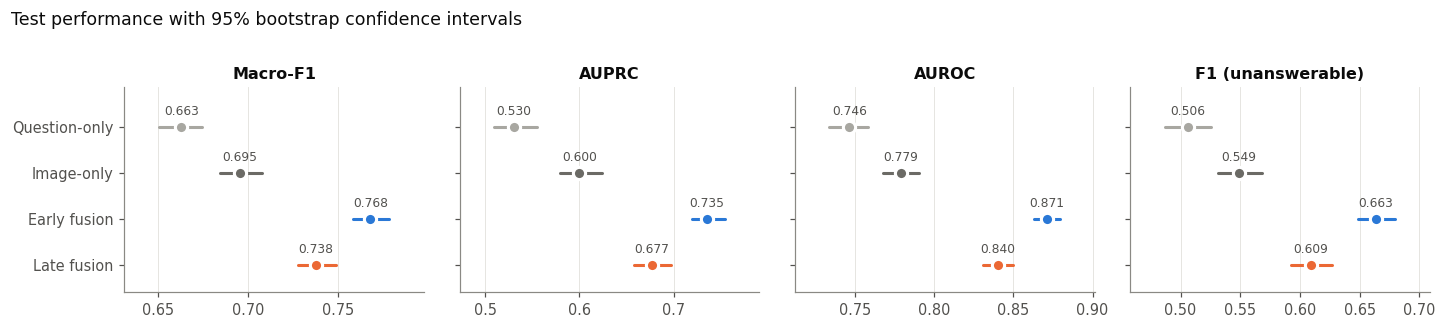

In [5]:
TABLE, BOOTS = ev.comparison_table(PRED, THR, y_test, EVAL_ORDER, "test", BOOT_IDX)
TABLE_DEV, _ = ev.comparison_table(PRED, THR, y_dev, EVAL_ORDER, "dev")

MAIN = ["macro_f1", "f1_unans", "balanced_acc", "auroc", "auprc"]
EXTRA = ["precision_unans", "recall_unans", "specificity", "mcc", "accuracy", "brier", "ece"]
display(ev.format_table(TABLE, MAIN))
display(ev.format_table(TABLE, EXTRA))

# Validation-to-test drop: a large drop means the validation-tuned choices do not transfer
print("Validation minus test:")
display((TABLE_DEV[["macro_f1", "auprc", "auroc"]] - TABLE[["macro_f1", "auprc", "auroc"]]).round(3))

TABLE.round(4).to_csv(EVAL_DIR / "test_metrics.csv")
ev.format_table(TABLE, MAIN + EXTRA).to_csv(EVAL_DIR / "test_metrics_formatted.csv")
ev.plot_metric_intervals(TABLE, EVAL_ORDER, path=EFIG / "metric_intervals.png");

## 2. Are the differences real?

Every pair of models is compared on the same bootstrap resamples (paired), and with the exact McNemar test on which test pairs each model gets right. Both p-values are Holm-corrected because many pairs are tested at once. A difference counts as significant only when its 95% CI excludes zero and the corrected p is below 0.05. The fusion-gain table checks team goal 2.

,model_a,model_b,diff,ci_lo,ci_hi,p_bootstrap,p_mcnemar,p_bootstrap_holm,p_mcnemar_holm,significant
0,Question-only,Image-only,-0.0325,-0.0500,-0.0167,0.001,0.0000,0.006,0.0000,True
1,Question-only,Early fusion,-0.1046,-0.1185,-0.0928,0.001,0.0000,0.006,0.0000,True
2,Question-only,Late fusion,-0.0746,-0.0892,-0.0617,0.001,0.0000,0.006,0.0000,True
3,Image-only,Early fusion,-0.0721,-0.0835,-0.0603,0.001,0.0000,0.006,0.0000,True
4,Image-only,Late fusion,-0.0421,-0.0510,-0.0332,0.001,0.0000,0.006,0.0000,True
5,Early fusion,Late fusion,0.0301,0.0202,0.0401,0.001,0.0009,0.006,0.0009,True


,vs,gain,ci_lo,ci_hi,ci_excludes_zero
fusion,,,,,
Early fusion,Image-only,0.0721,0.0603,0.0835,True
Late fusion,Image-only,0.0421,0.0332,0.0510,True


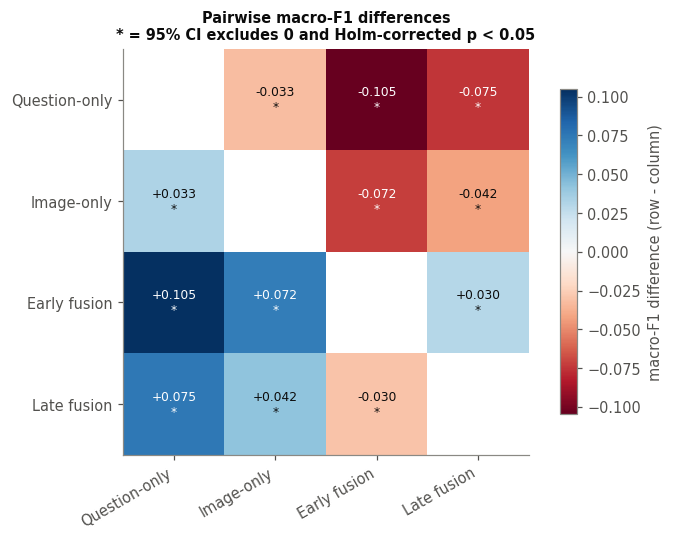

In [6]:
PAIRS = ev.pairwise_significance(PRED, THR, y_test, BOOTS, EVAL_ORDER)
display(PAIRS.round(4))
PAIRS.round(4).to_csv(EVAL_DIR / "pairwise_significance.csv", index=False)
ev.plot_significance_matrix(PAIRS, EVAL_ORDER, path=EFIG / "significance_matrix.png");

GAINS = ev.fusion_gain(TABLE, BOOTS, fusions=FUSIONS)
display(GAINS.round(4))
GAINS.round(4).to_csv(EVAL_DIR / "fusion_gain.csv")

## 3. Curves, errors and calibration

ROC shows ranking quality over all thresholds; precision-recall is more informative here because unanswerable pairs are the minority. Confusion matrices show which kind of error each model makes at its operating threshold. The reliability diagram shows whether a predicted 0.7 really means a 70% chance of being unanswerable, which matters if the score is shown to users.

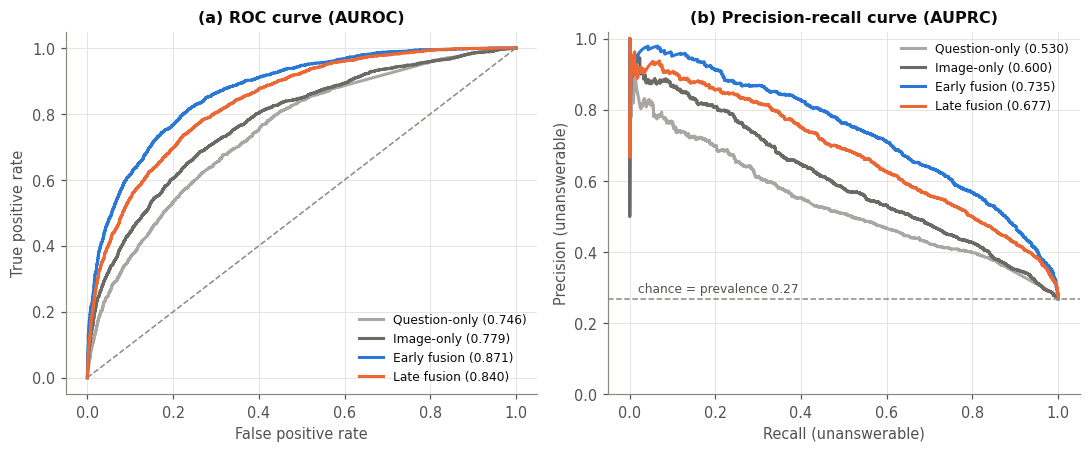

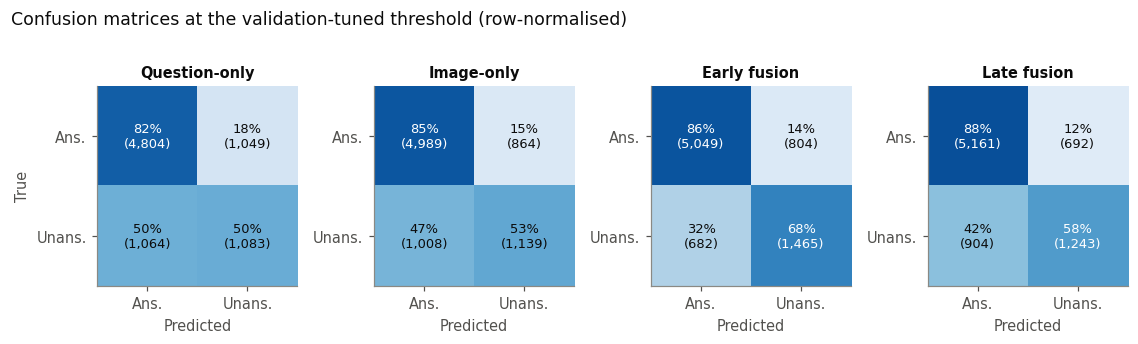

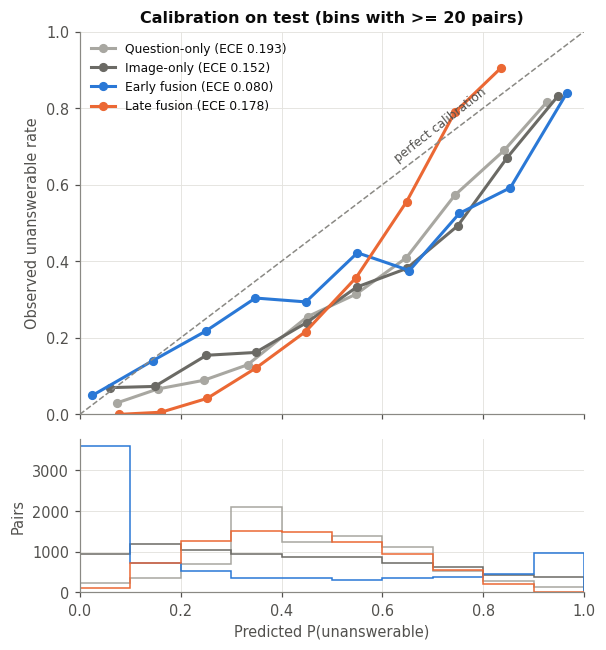

In [7]:
ev.plot_roc_pr(PRED, y_test, EVAL_ORDER, path=EFIG / "roc_pr.png");
ev.plot_confusion_grid(PRED, THR, y_test, EVAL_ORDER, path=EFIG / "confusion_matrices.png");
ev.plot_reliability(PRED, y_test, EVAL_ORDER, path=EFIG / "reliability.png");

## 4. Robustness across seeds

One seed can flatter or penalise a model by chance. With the team run folders, the seeds already trained are used; otherwise each trainable model is retrained with three seeds; the table reports mean +/- standard deviation on test. Takes roughly 3x the training time (about 2 minutes on a T4 for the heads). Set `RUN_SEEDS = False` to skip.

In [8]:
RUN_SEEDS = True
SEEDS = [CONFIG["seed"], CONFIG["seed"] + 1, CONFIG["seed"] + 2]
SEED_TABLES = []
if SOURCE == "runs":
    # every model was already trained with several seeds: thresholds re-tuned on each seed's dev predictions
    for s in RUN_SEEDS_AVAILABLE:
        pred_s, thr_s = seed_predictions(s)
        if DEV_CHECK:
            pred_s = {n: {**v, "test": v["dev"]} for n, v in pred_s.items()}
        SEED_TABLES.append(ev.comparison_table(pred_s, thr_s, y_test, EVAL_ORDER, "test")[0])
    if len(SEED_TABLES) > 1:
        SEED_SUMMARY = ev.seed_summary(SEED_TABLES)
        display(ev.format_seed_summary(SEED_SUMMARY, ["macro_f1", "auprc", "auroc", "f1_unans"]))
        SEED_SUMMARY.round(4).to_csv(EVAL_DIR / "seed_summary.csv")
    else:
        print("Only one seed in runs/: train more seeds for the robustness table.")
elif RUN_SEEDS and not CAN_RETRAIN:
    print("Skipped: retraining needs the main notebook's training code in this session.")
elif RUN_SEEDS:
    from sklearn.metrics import average_precision_score
    for s in SEEDS:
        cfg = {**CONFIG, "seed": s}
        pred_s, thr_s = {}, {}
        for name, (make, get_batch) in SPECS.items():
            set_seed(s)
            m, _, _ = train(make(), get_batch, cfg)
            pred_s[name] = {sp: predict(m, get_batch, IDX[sp]) for sp in ("dev", "test")}
            thr_s[name] = tune_threshold(pred_s[name]["dev"], y_dev)
        # Late fusion rebuilt from this seed's unimodal heads, weight tuned on validation only
        if "Late fusion" in EVAL_ORDER:
            ws = np.linspace(0, 1, 21)
            w = float(ws[np.argmax([average_precision_score(
                y_dev, w * pred_s["Question-only"]["dev"] + (1 - w) * pred_s["Image-only"]["dev"]) for w in ws])])
            pred_s["Late fusion"] = {sp: w * pred_s["Question-only"][sp] + (1 - w) * pred_s["Image-only"][sp]
                                     for sp in ("dev", "test")}
            thr_s["Late fusion"] = tune_threshold(pred_s["Late fusion"]["dev"], y_dev)
        names = [n for n in EVAL_ORDER if n in pred_s]
        SEED_TABLES.append(ev.comparison_table(pred_s, thr_s, y_test, names, "test")[0])
        print(f"seed {s} done")
    SEED_SUMMARY = ev.seed_summary(SEED_TABLES)
    display(ev.format_seed_summary(SEED_SUMMARY, ["macro_f1", "auprc", "auroc", "f1_unans"]))
    SEED_SUMMARY.round(4).to_csv(EVAL_DIR / "seed_summary.csv")

Only one seed in runs/: train more seeds for the robustness table.


## 5. Learning curves

Train loss is measured in evaluation mode on a fixed 5,000-pair training subset, so it is comparable with validation loss. A widening gap after the best epoch is overfitting; early stopping on validation AUPRC keeps the dotted epoch.

,epochs_run,best_epoch,train_loss_best,dev_loss_best,gap_best,gap_last,dev_auprc_best
model,,,,,,,
Early fusion,12,8,0.1903,0.4822,0.2919,0.4453,0.7416
Image-only,7,3,0.4307,0.5875,0.1568,0.4499,0.6201
Question-only,8,4,0.5782,0.6156,0.0375,0.0644,0.5676


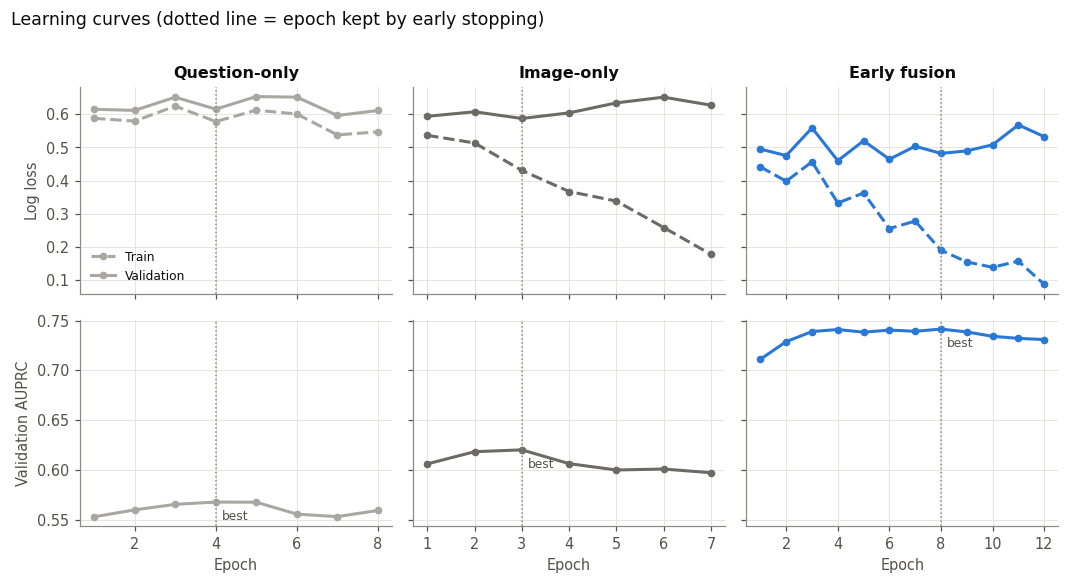

In [9]:
LC = ev.learning_curve_summary(HIST)
display(LC.round(4))
LC.round(4).to_csv(EVAL_DIR / "learning_curves_summary.csv")
ev.plot_learning_curves(HIST, EVAL_ORDER, path=EFIG / "learning_curves.png");

## 6. Speed and size

Team goal 3 is at most 100 ms per query on a T4. A query is one photo and one question, so latency is measured at batch size 1:

- **Head latency**: the fusion head alone on cached features.
- **Encoder latency**: decode, resize and normalise the photo, tokenise the question, run frozen ViT-B/16 and BERT-base. All models share this cost.
- **End-to-end** = encoder + head (median of each). This is what a user waits for.

Parameter counts are trainable head parameters; the frozen encoders (about 86M ViT + 110M BERT parameters) are shared by all models.

Latency skipped: it needs MODELS (see the note at the top) and the main notebook's feature-extraction code in this session. The size and training-time columns still work.


,macro_f1,auprc,params,train_sec,epochs,peak_vram_gb
model,,,,,,
Question-only,0.6630,0.5303,198657,2.00,8,0.030
Image-only,0.6955,0.5999,198657,1.68,7,0.030
Early fusion,0.7676,0.7352,396801,3.12,12,0.046
Late fusion,0.7376,0.6766,397314,3.68,8+7,0.030


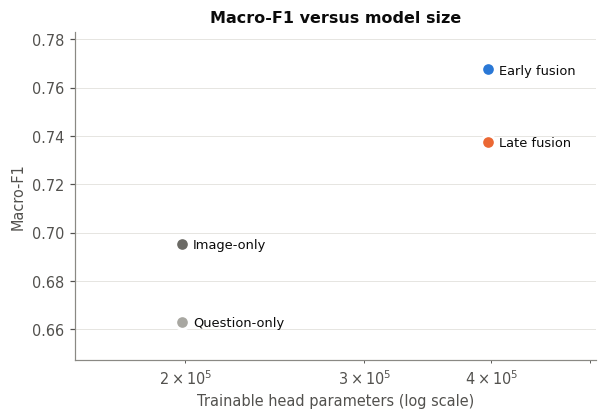

In [10]:
LAT = {}
if not CAN_TIME:
    print("Latency skipped: it needs MODELS (see the note at the top) and the main notebook's "
          "feature-extraction code in this session. The size and training-time columns still work.")
else:
    import torch
    from transformers import AutoModel, AutoImageProcessor

    sync = torch.cuda.synchronize if DEVICE == "cuda" else None
    q_idx = int(IDX["test"][0])
    for name, (make, get_batch) in SPECS.items():
        if name in MODELS:
            mdl = MODELS[name].eval()
            def head_call(mdl=mdl, gb=get_batch):
                with torch.no_grad():
                    return mdl(*gb([q_idx]))
            LAT[name] = {"head_ms": ev.benchmark(head_call, sync=sync)["median_ms"]}
    if "Late fusion" in EVAL_ORDER and {"Question-only", "Image-only"} <= LAT.keys():
        LAT["Late fusion"] = {"head_ms": LAT["Question-only"]["head_ms"] + LAT["Image-only"]["head_ms"]}

    proc = AutoImageProcessor.from_pretrained(CONFIG["image_model"])
    vit = AutoModel.from_pretrained(CONFIG["image_model"]).to(DEVICE).eval()
    bert = AutoModel.from_pretrained(CONFIG["text_model"]).to(DEVICE).eval()
    one_photo = PhotoDataset([meta["path"].iloc[q_idx]], CONFIG["image_size"], proc.image_mean, proc.image_std)
    one_question = [meta["question"].iloc[q_idx]]

    def encode_one():
        x, _ = one_photo[0]                              # includes JPEG decode and resize
        with torch.no_grad(), autocast():
            vit(pixel_values=x.unsqueeze(0).to(DEVICE))
            enc = tokenizer(one_question, padding="max_length", truncation=True,
                            max_length=CONFIG["max_q_tokens"], return_tensors="pt").to(DEVICE)
            bert(**enc)

    ENC = ev.benchmark(encode_one, repeats=30, sync=sync)
    for name in LAT:
        LAT[name]["end_to_end_ms"] = ENC["median_ms"] + LAT[name]["head_ms"]
    print(f"Encoders per query: median {ENC['median_ms']:.1f} ms, p95 {ENC['p95_ms']:.1f} ms")
    del vit, bert
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

EFF =ev.efficiency_table(TABLE, COST, LAT, composite=COMPOSITE)
display(EFF.round(4))
EFF.round(4).to_csv(EVAL_DIR / "efficiency.csv")
ev.plot_efficiency(EFF, EVAL_ORDER, budget_ms=100, path=EFIG / "efficiency.png");

## 7. Failure cases

**Per-pair predictions** are saved for Barath's subgroup and threshold analysis, so both sections use identical predictions.

**Complementarity:** test pairs are grouped by which single-modality model is right. If fusion worked perfectly it would be right in every "only one right" group; the gap to the single-modality oracle is unexploited complementary signal.

**Error profile:** the descriptors of false negatives and false positives compared with correct predictions. `unans_votes` is the number of crowd workers (of 10) who said "unanswerable"; it is used only for analysis, never as a model input.

**Galleries:** the most confident mistakes of the best model, to read by eye for patterns (blur, text, framing, ambiguous labels).

,share,n,Early fusion,Late fusion
group,,,,
Both right,0.583,4666,0.959,0.996
Only question right,0.153,1221,0.642,0.464
Only image right,0.183,1462,0.741,0.808
Both wrong,0.081,651,0.261,0.015


Share of test pairs by number of models wrong:


,proportion
n_models_wrong,
0,0.558
1,0.205
2,0.092
3,0.085
4,0.060


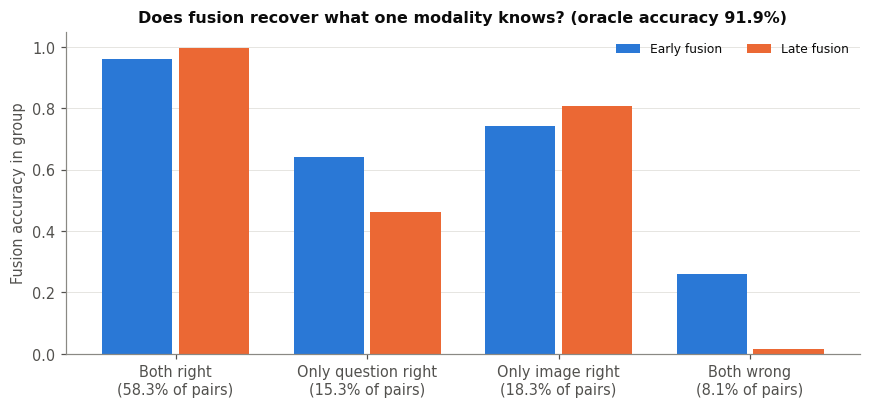

In [11]:
test_meta = meta.iloc[IDX["test"]][[c for c in ev.META_COLS if c in meta.columns and c != "split"]]
PP = ev.per_pair_predictions(test_meta, PRED, THR, y_test, EVAL_ORDER)
PP.drop(columns=["path"], errors="ignore").to_csv(EVAL_DIR / "per_pair_predictions_test.csv", index=False)

COMP = ev.complementarity(PP, FUSIONS)
display(COMP.round(3))
ev.plot_complementarity(COMP, FUSIONS, path=EFIG / "complementarity.png");

# Pairs that every model gets wrong: the hard core no fusion strategy fixes
print("Share of test pairs by number of models wrong:")
display(PP["n_models_wrong"].value_counts(normalize=True).sort_index().round(3))

In [14]:
BEST = TABLE["macro_f1"].idxmax()
HAS_TEXT = "question" in PP.columns and "question" in meta.columns
if not HAS_TEXT:
    print("Note: no question text found (features/<part>/meta.csv is not in the Drive folder), so the "
          "question-based columns and photo galleries are skipped. The error profile uses the other columns.")

if HAS_TEXT:
    questions = PP["question"].fillna("").astype(str).str.lower()
    TOP_Q = set(meta.loc[IDX["train"], "question"].dropna().astype(str).str.lower().value_counts().head(20).index)
    PP["frequent_question"] = questions.isin(TOP_Q).astype(int)
    PP["reading_question"] = questions.str.contains(
        r"\b(?:say|read|written|text|label|expir|brand|name)\b").astype(int)

PROFILE_COLS = [c for c in ["q_words", "unans_votes", "consensus", "frequent_question", "reading_question",
                            "gate_q"] if c in PP.columns]
if PROFILE_COLS:
    PROFILE = ev.describe_outcomes(PP, BEST, PROFILE_COLS)
else:                                   # only counts of TP / FN / TN / FP are available
    o = ev.outcome(PP, BEST)
    PROFILE = o.value_counts().reindex(["TP", "FN", "TN", "FP"]).fillna(0).astype(int).to_frame("n")
display(PROFILE.round(3))
PROFILE.round(4).to_csv(EVAL_DIR / f"error_profile_{BEST}.csv")

FN = ev.top_errors(PP, BEST, "FN", k=8)
FP = ev.top_errors(PP, BEST, "FP", k=8)
if HAS_TEXT:
    ev.plot_failure_gallery(FN, BEST, "Most confident false negatives: unanswerable, predicted answerable",
                            path=EFIG / "failures_false_negatives.png");
    ev.plot_failure_gallery(FP, BEST, "Most confident false positives: answerable, predicted unanswerable",
                            path=EFIG / "failures_false_positives.png");
    if "path" not in PP or not Path(str(PP["path"].iloc[0])).exists():
        print("Note: photos are not on this session's disk, so the galleries show 'image unavailable'.")
TOP_ERRORS = pd.concat([FN.assign(kind="FN"), FP.assign(kind="FP")]).drop(columns=["path"], errors="ignore")
display(TOP_ERRORS[[c for c in ["kind", "pair_id", "image", "question", "y", f"p::{BEST}", "unans_votes"]
                    if c in TOP_ERRORS.columns]].round(3))
TOP_ERRORS.to_csv(EVAL_DIR / f"top_errors_{BEST}.csv", index=False)

Note: no question text found (features/<part>/meta.csv is not in the Drive folder), so the question-based columns and photo galleries are skipped. The error profile uses the other columns.


,n
TP,1465
FN,682
TN,5049
FP,804


,kind,image,y,p::Early fusion
699,FN,VizWiz_test_00000699.jpg,1,0.000
1571,FN,VizWiz_test_00001571.jpg,1,0.000
6777,FN,VizWiz_test_00006777.jpg,1,0.001
4532,FN,VizWiz_test_00004532.jpg,1,0.001
1296,FN,VizWiz_test_00001296.jpg,1,0.001
5002,FN,VizWiz_test_00005002.jpg,1,0.001
5792,FN,VizWiz_test_00005792.jpg,1,0.002
6403,FN,VizWiz_test_00006403.jpg,1,0.002
7822,FP,VizWiz_test_00007822.jpg,0,1.000
7498,FP,VizWiz_test_00007498.jpg,0,1.000


**Modality ablation.** At test time one modality is replaced by its training-set mean, so the model sees "no information" from it while the input shape stays the same. The drop in AUPRC measures how much each fusion model relies on each modality. For cross-attention, each question token is replaced by the mean token, but the attention mask is kept, so question length still leaks through. Note this when reporting.

In [15]:
import torch

def chunk_mean(arr, idx, bs=1024, mask=None):
    # Mean over the rows in idx without loading them all into memory at once
    total, count = 0, 0
    for i in range(0, len(idx), bs):
        b = torch.as_tensor(idx[i:i + bs])
        x = arr[b].float()
        if mask is None:
            total, count = total + x.sum(0), count + len(b)
        else:
            m = mask[b].float().unsqueeze(-1)
            total, count = total + (x * m).sum((0, 1)), count + m.sum()
    return total / count

ABL_SCORES = {}
if not CAN_ABLATE:
    print("Ablation skipped: it needs MODELS (see the note at the top) and the cached features in this session.")
else:
    tr = IDX["train"]
    if "Early fusion" in MODELS:
        dq, mean_qi = X_Q.shape[1], chunk_mean(X_QI, tr)
        def early_batch(mode):
            def gb(idx):
                x = X_QI[torch.as_tensor(idx)].float()
                if mode == "no_question":
                    x[:, :dq] = mean_qi[:dq]
                if mode == "no_image":
                    x[:, dq:] = mean_qi[dq:]
                return (x.to(DEVICE),)
            return gb
        ABL_SCORES["Early fusion"] = {
            "full": PRED["Early fusion"]["test"],
            "question replaced by mean": predict(MODELS["Early fusion"], early_batch("no_question"), IDX["test"]),
            "image replaced by mean": predict(MODELS["Early fusion"], early_batch("no_image"), IDX["test"])}
    if "Cross-attention" in MODELS:
        mean_img_tok = chunk_mean(T["img_tok"], tr).to(DEVICE)
        mean_txt_tok = chunk_mean(T["txt_tok"], tr, mask=T["txt_mask"]).to(DEVICE)
        def ca_batch(mode):
            def gb(idx):
                q, m, v = token_batch(idx)
                if mode == "no_image":
                    v = mean_img_tok.expand_as(v).clone()
                if mode == "no_question":
                    q = mean_txt_tok.expand_as(q).clone()
                return q, m, v
            return gb
        ABL_SCORES["Cross-attention"] = {
            "full": PRED["Cross-attention"]["test"],
            "question replaced by mean": predict(MODELS["Cross-attention"], ca_batch("no_question"), IDX["test"]),
            "image replaced by mean": predict(MODELS["Cross-attention"], ca_batch("no_image"), IDX["test"])}
if ABL_SCORES:
    ABL = ev.ablation_table(ABL_SCORES, y_test, THR)
    display(ABL.round(4))
    ABL.round(4).to_csv(EVAL_DIR / "modality_ablation.csv")
    ev.plot_ablation(ABL, path=EFIG / "modality_ablation.png");

Ablation skipped: it needs MODELS (see the note at the top) and the cached features in this session.


## 8. Team goals and findings

The goal table checks team goals 2 and 3 for each fusion model. The findings list is generated from the tables above, so every number in it can be traced; use it as the factual skeleton of the Evaluation section, then add the interpretation.

In [16]:
LAT_E2E = {n: v["end_to_end_ms"] for n, v in LAT.items() if "end_to_end_ms" in v} if "LAT" in globals() else None
GOALS = ev.goal_check(TABLE, GAINS, LAT_E2E)
display(GOALS)
GOALS.to_csv(EVAL_DIR / "goal_check.csv")

FINDINGS = ev.findings(TABLE, PAIRS, GAINS, EFF if "EFF" in globals() else None, COMP, LC)
print("\n".join("- " + f for f in FINDINGS))
ev.save_json({"order": EVAL_ORDER, "thresholds": {n: THR[n] for n in EVAL_ORDER}, "test_metrics": TABLE,
              "fusion_gain": GAINS, "goals": GOALS, "complementarity": COMP,
              "oracle_accuracy": COMP.attrs["oracle_accuracy"], "findings": FINDINGS},
             EVAL_DIR / "evaluation_summary.json")
print(f"\nTables in {EVAL_DIR}, figures in {EFIG}")

,macro_f1,macro_f1>=0.78,auprc,auprc>=0.75,gain_ci_excludes_0
model,,,,,
Early fusion,0.767608,False,0.735205,False,True
Late fusion,0.737550,False,0.676631,False,True


- Best macro-F1: Early fusion at 0.768 (95% CI 0.758 to 0.778), AUPRC 0.735, AUROC 0.871.
- Early fusion vs Image-only: macro-F1 +0.072 (95% CI +0.060 to +0.083); the CI excludes zero.
- Late fusion vs Image-only: macro-F1 +0.042 (95% CI +0.033 to +0.051); the CI excludes zero.
- Calibration: ECE ranges from 0.080 (Early fusion) to 0.193 (Question-only).
- Size: Late fusion has 1.0x the parameters of Early fusion and trains 1.2x longer, for a macro-F1 difference of -0.030.
- Only question right (15.3% of pairs): best recovery by Early fusion, 64.2% correct.
- Only image right (18.3% of pairs): best recovery by Late fusion, 80.8% correct.
- Single-modality oracle accuracy 91.9% vs best fusion accuracy 81.4%: the remaining headroom.
- Largest train/validation loss gap at the kept epoch: Early fusion (0.292).

Tables in /content/drive/MyDrive/vizwiz_fusion/evaluation, figures in /content/drive/MyDrive/vizwiz_fusion/evaluation/figures


In [18]:
%cd /content
!rm -rf vizwiz-answerability-fusion
!git clone https://github.com/vishnuvardhan0ffl/vizwiz-answerability-fusion.git
%cd /content/vizwiz-answerability-fusion
!git checkout -b ruturaj/evaluation

/content
Cloning into 'vizwiz-answerability-fusion'...
remote: Enumerating objects: 76, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (55/55), done.
remote: Total 76 (delta 23), reused 49 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (76/76), 907.52 KiB | 1.09 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/vizwiz-answerability-fusion
Switched to a new branch 'ruturaj/evaluation'


In [ ]:
from google.colab import files
import shutil

uploaded = files.upload()
name = next(iter(uploaded))
shutil.move(name, "notebooks/04_evaluation.ipynb")
!git status

## References (evaluation methods)

Brier, GW 1950, 'Verification of forecasts expressed in terms of probability', *Monthly Weather Review*, vol. 78, no. 1, pp. 1-3.

Dietterich, TG 1998, 'Approximate statistical tests for comparing supervised classification learning algorithms', *Neural Computation*, vol. 10, no. 7, pp. 1895-1923.

Efron, B & Tibshirani, RJ 1993, *An introduction to the bootstrap*, Chapman & Hall, New York.

Guo, C, Pleiss, G, Sun, Y & Weinberger, KQ 2017, 'On calibration of modern neural networks', in *Proceedings of the 34th international conference on machine learning (ICML 2017)*, PMLR, vol. 70, pp. 1321-1330.

Holm, S 1979, 'A simple sequentially rejective multiple test procedure', *Scandinavian Journal of Statistics*, vol. 6, no. 2, pp. 65-70.

McNemar, Q 1947, 'Note on the sampling error of the difference between correlated proportions or percentages', *Psychometrika*, vol. 12, no. 2, pp. 153-157.

Saito, T & Rehmsmeier, M 2015, 'The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets', *PLoS ONE*, vol. 10, no. 3, article no. e0118432.